<a href="https://colab.research.google.com/github/Dharshini9981/ML_T9_SVM/blob/main/ML_T9_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (35742, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0     0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1     0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2     1 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3     1 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4     2 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

     

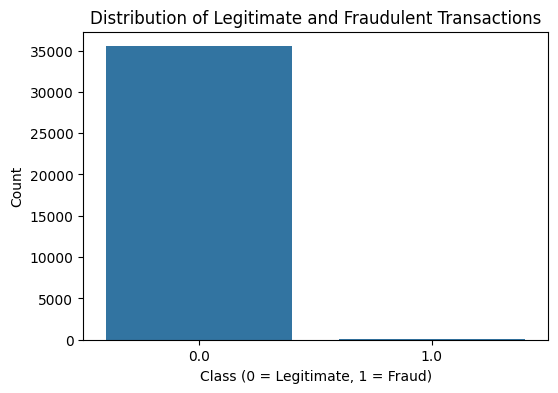

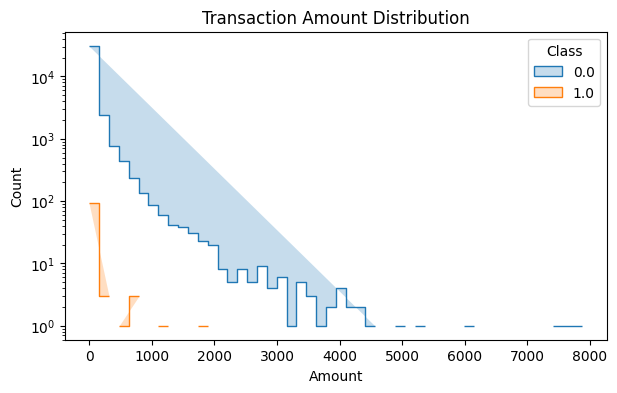

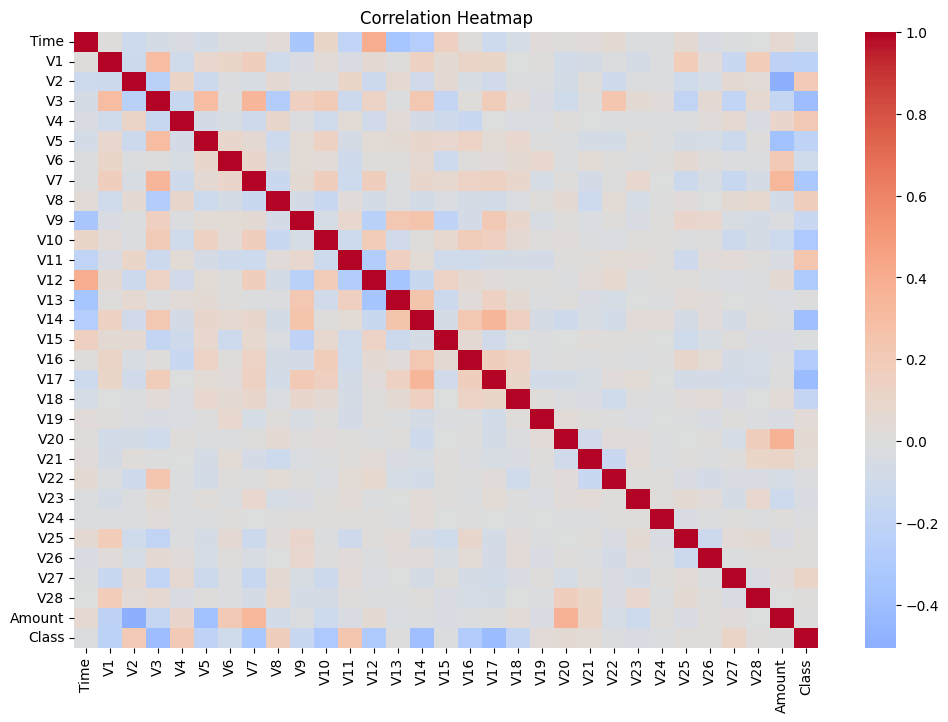

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

df = pd.read_csv('/content/creditcard.csv')

print("Dataset Shape:", df.shape)
print(df.head())
print(df.info())
print("Missing Values:\n", df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.dropna()

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Class')
plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='Amount', hue='Class', bins=50, log_scale=(False, True), element='step')
plt.title("Transaction Amount Distribution")
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.title("Correlation Heatmap")
plt.show()


In [ ]:
# Fix: Only apply train_test_split for sampling if the dataset is larger than the target sample size
target_sample_size = 30000
if len(df) > target_sample_size:
    df, _ = train_test_split(df, train_size=target_sample_size, stratify=df['Class'], random_state=42)

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', C=1, class_weight='balanced'))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [ ]:
print("Linear SVM Performance")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Linear SVM Performance
Accuracy: 0.9843333333333333
Precision: 0.14018691588785046
Recall: 0.8823529411764706
F1 Score: 0.24193548387096775
Confusion Matrix:
 [[5891   92]
 [   2   15]]
              precision    recall  f1-score   support

         0.0       1.00      0.98      0.99      5983
         1.0       0.14      0.88      0.24        17

    accuracy                           0.98      6000
   macro avg       0.57      0.93      0.62      6000
weighted avg       1.00      0.98      0.99      6000



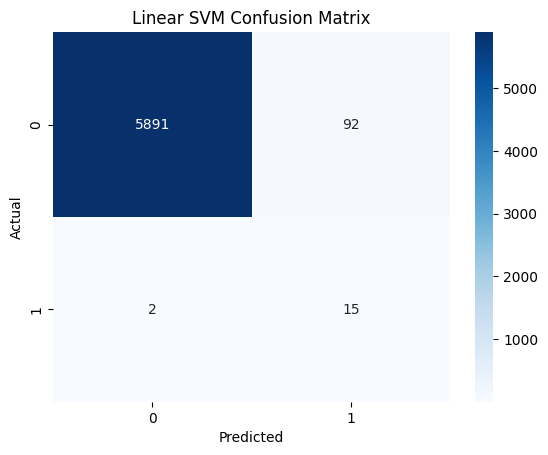

In [ ]:
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title("Linear SVM Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
#NON - LINEAR SVM

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

df = pd.read_csv('/content/creditcard.csv')

print("Dataset Shape:", df.shape)
print(df.head())
print(df.info())
print("Missing Values:\n", df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.dropna()

Dataset Shape: (41683, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0     0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1     0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2     1 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3     1 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4     2 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

     

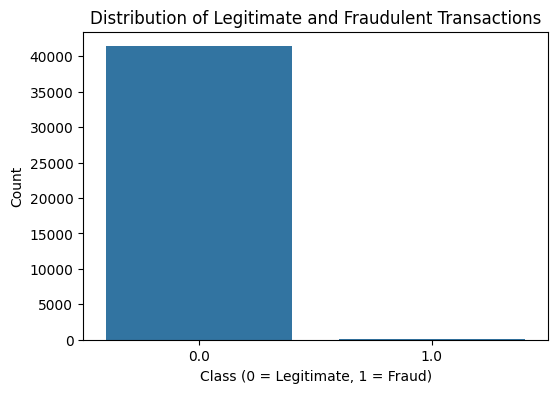

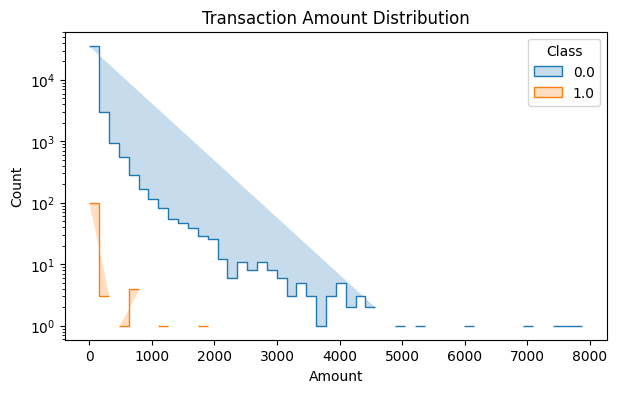

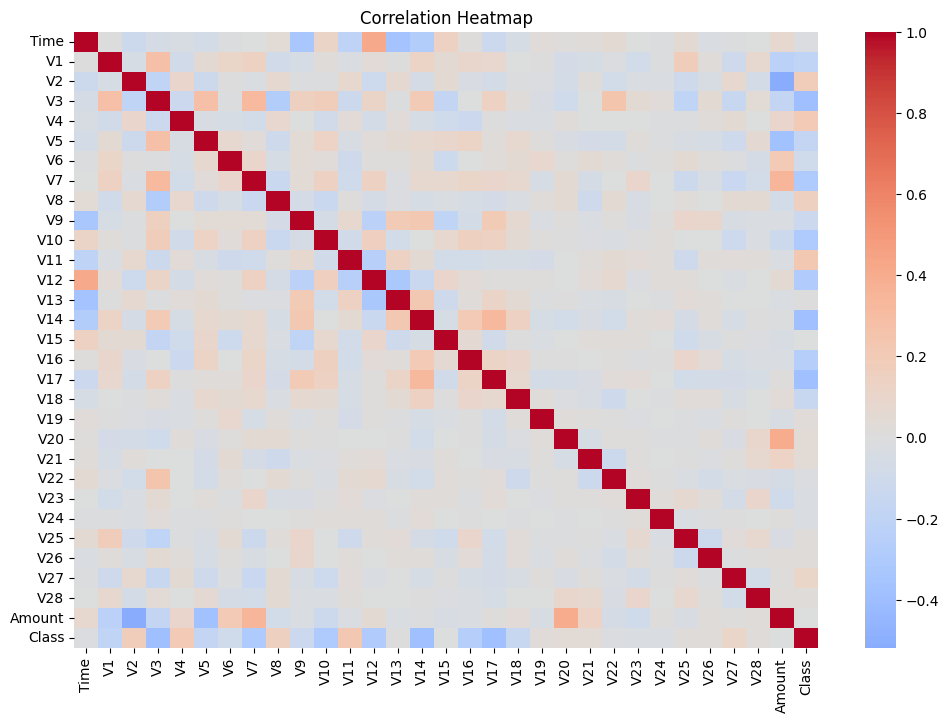

In [ ]:

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Class')
plt.title("Distribution of Legitimate and Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='Amount', hue='Class', bins=50, log_scale=(False, True), element='step')
plt.title("Transaction Amount Distribution")
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
sample_size = min(30000, len(df))
df, _ = train_test_split(df, train_size=sample_size, stratify=df['Class'], random_state=42)

X = df.drop('Class', axis=1)
y = df['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1, gamma='scale', class_weight='balanced'))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Non-linear SVM (RBF) Performance")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Non-linear SVM (RBF) Performance
Accuracy: 0.9981666666666666
Precision: 0.6666666666666666
Recall: 0.625
F1 Score: 0.6451612903225806
Confusion Matrix:
 [[5979    5]
 [   6   10]]
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      5984
         1.0       0.67      0.62      0.65        16

    accuracy                           1.00      6000
   macro avg       0.83      0.81      0.82      6000
weighted avg       1.00      1.00      1.00      6000

